#HomeWork

### Introduction to the Wine Quality Dataset


In this exercise, we will explore the Wine Quality dataset, which contains information about various wine samples and their quality ratings. We will learn how to visualize the data and train a simple machine learning model to classify the quality of the wines based on their features.


## Load the Required Libraries


In the next cell, you will load the necessary libraries. Run the code below to import the libraries we need for our analysis.


In [13]:
# Load the required libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn import datasets
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC


##Load the Wine Quality Dataset

##Load the Wine Quality Dataset
Now, we will load the Wine Quality dataset.


In [14]:
# Load the Wine Quality dataset
wine = datasets.load_wine()
X = wine.data  # Features
y = wine.target  # Target variable (wine quality)

# Create a DataFrame for better visualization
wine_df = pd.DataFrame(X, columns=wine.feature_names)
wine_df['target'] = y

# Display the feature names
print("Feature names:", wine.feature_names)
# Display the first few rows of the dataset
wine_df.head()


Feature names: ['alcohol', 'malic_acid', 'ash', 'alcalinity_of_ash', 'magnesium', 'total_phenols', 'flavanoids', 'nonflavanoid_phenols', 'proanthocyanins', 'color_intensity', 'hue', 'od280/od315_of_diluted_wines', 'proline']


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,target
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0,0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0,0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0,0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0,0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0,0


##Part1:Visualize the Data

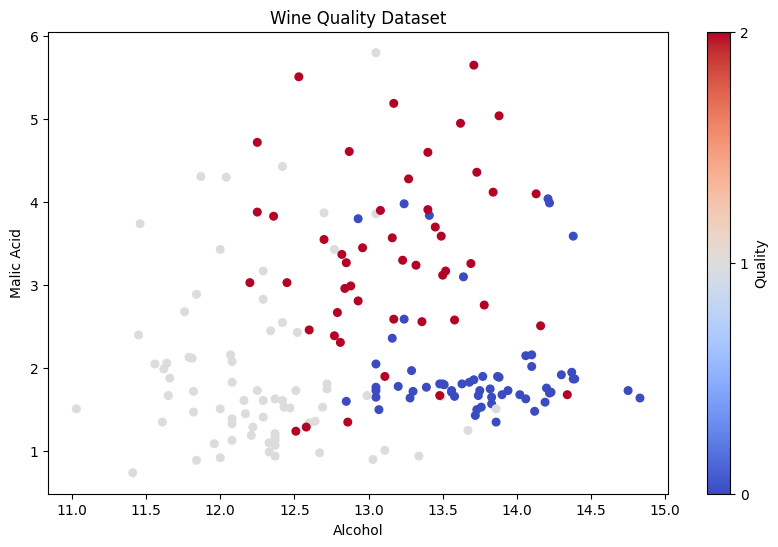

In [15]:
# Visualize the data
plt.figure(figsize=(10, 6))
plt.scatter(wine_df['alcohol'], wine_df['malic_acid'], c=wine_df['target'], cmap='coolwarm', s=30)

plt.title("Wine Quality Dataset")
plt.xlabel("Alcohol")
plt.ylabel("Malic Acid")

plt.colorbar(ticks=np.unique(y), label='Quality')
plt.show()

## Standardize the Features


Before training our model, we need to standardize the features. Run the code below to standardize the features.

In [16]:
# Standardize features
scaler = StandardScaler()
X2 = scaler.fit_transform(X)  # Standardize features

## Part2: Split the Data



In [17]:
# Split the dataset into training and testing sets (same as the Load DataSet example)
X_train, X_test, y_train, y_test = train_test_split(X2, y, test_size=0.3, random_state=42)
print("Training samples:", X_train.shape[0], "| Testing samples:", X_test.shape[0])


Training samples: 124 | Testing samples: 54


## Part 3 : create a Decision Tree and a Logistic Regression model to classify the wine quality. We will print the accuracy for each model. The code for SVM will serve as an example, and you should complete the code for Decision Tree and Logistic Regression accordingly.

###SVM

#### Train the SVM Model

In [18]:
svm = SVC(kernel='linear')
svm.fit(X_train, y_train)

SVC(kernel='linear')

####make prediction

In [19]:
y_pred = svm.predict(X_test)

#### Evaluate the Model



Now that we have trained our model, we can evaluate its performance on the test set. Run the code below to make predictions and calculate the accuracy.

In [20]:
# Make predictions and calculate accuracy
accuracy = accuracy_score(y_test , y_pred)
print(f"Accuracy of the SVM model: {accuracy:.2f}")


Accuracy of the SVM model: 0.98


### Decision Tree model

Accuracy of the Decision Tree model: 0.96


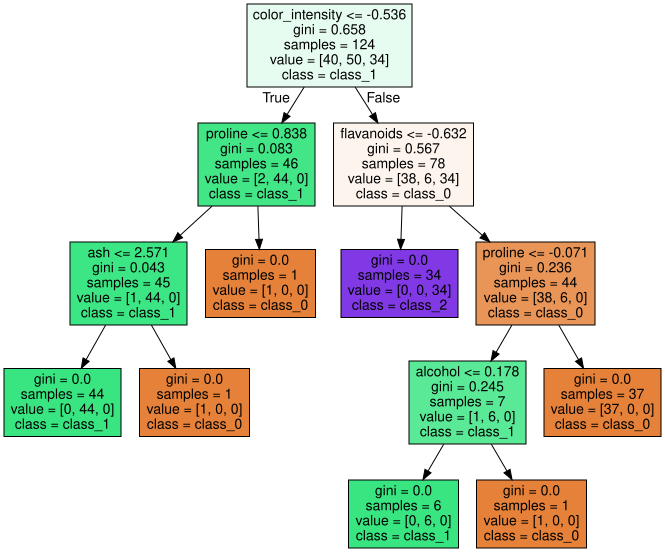

In [23]:
# Train the Decision Tree model
tree = DecisionTreeClassifier(random_state=42)
tree.fit(X_train, y_train)

# Make predictions
y_pred_tree = tree.predict(X_test)

# Evaluate the model
accuracy_tree = accuracy_score(y_test, y_pred_tree)
print(f"Accuracy of the Decision Tree model: {accuracy_tree:.2f}")

# Visualization of the decision tree - using only the first 2 feature names
dot_data = export_graphviz(tree, out_file=None, feature_names=wine.feature_names, class_names=wine.target_names, filled=True)
graph = graphviz.Source(dot_data)
graph.render("wine_decision_tree", format="png")
graph


###Logistic Regression

Accuracy of the Logistic Regression model: 0.98


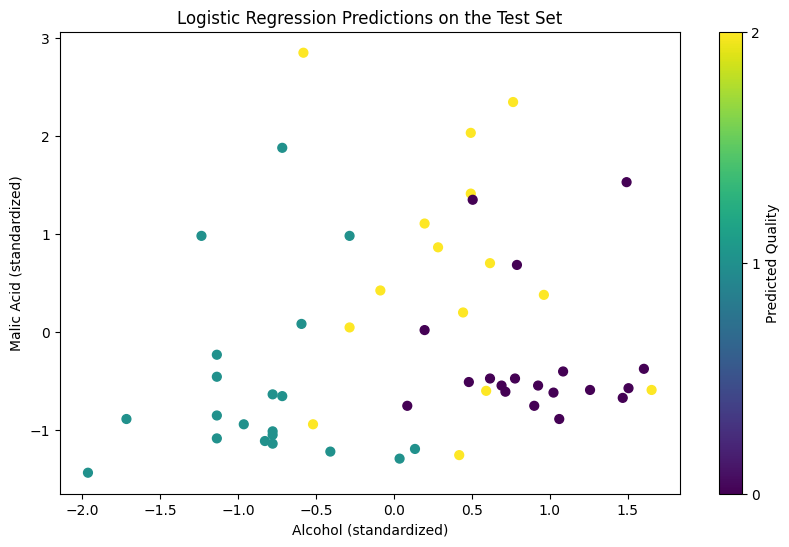

In [24]:

# Train the Logistic Regression model
log_regressor = LogisticRegression(max_iter=200)
log_regressor.fit(X_train, y_train)

# Make predictions
y_pred_log = log_regressor.predict(X_test)

# Evaluate the model
accuracy_log = accuracy_score(y_test, y_pred_log)
print(f"Accuracy of the Logistic Regression model: {accuracy_log:.2f}")

# Visualization of the predicted classes (first two standardized features)
plt.figure(figsize=(10, 6))
plt.scatter(X_test[:, 0], X_test[:, 1], c=y_pred_log, cmap='viridis', s=40)
plt.title("Logistic Regression Predictions on the Test Set")
plt.xlabel("Alcohol (standardized)")
plt.ylabel("Malic Acid (standardized)")
plt.colorbar(ticks=np.unique(y), label='Predicted Quality')
plt.show()